# Figure 1: phase diagram in $(\alpha_1, \alpha_2)$

Final camera-ready version. No data: the regions are drawn from the model's defining inequalities.

The figure is drawn at its printed size (`figsize` width = 2.75 in = `0.5\textwidth`, the width used in `\includegraphics`), so the font sizes below are the sizes on the page: tick labels 7 pt, axis labels 8 pt, title 9 pt, region labels 7 pt. Saved without `bbox_inches="tight"` so the PDF is exactly 2.75 in wide and LaTeX does not rescale it.

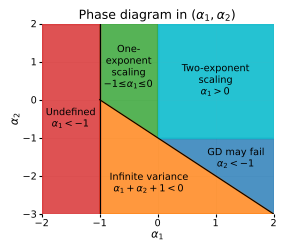

In [ ]:
# Phase diagram in (alpha1, alpha2), exported to PDF, PNG and SVG at printed size

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

plt.rcParams.update({"font.family": "DejaVu Sans",
                     "mathtext.fontset": "dejavusans",
                     "pdf.fonttype": 42})

# Printed sizes (pt): the figure is drawn at its size on the page
FIG_W, FIG_H = 2.75, 2.4          # inches; 0.5\textwidth in the NeurIPS template
FS_TICK, FS_LABEL, FS_TITLE, FS_REGION = 7, 8, 9, 7

# Plot bounds (alpha1 < -1 is undefined, so only one unit of it is shown)
x_min, x_max = -2, 2
y_min, y_max = -3, 2

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H), layout="constrained")

# Colors
COL_UNDEFINED = "#d62728"   # red
COL_INFVAR   = "#ff7f0e"    # orange
COL_CONV     = "#1f77b4"    # blue
COL_NODB     = "#2ca02c"    # green
COL_OK       = "#17becf"    # cyan

# Undefined region: alpha1 < -1
ax.add_patch(
    Polygon(
        [(x_min, y_min), (-1, y_min), (-1, y_max), (x_min, y_max)],
        color=COL_UNDEFINED,
        alpha=0.8,
        zorder=5
    )
)
ax.text(-1.5, -0.5, "Undefined\n$\\alpha_1 < -1$", fontsize=FS_REGION,
        ha="center", va="center", zorder=10)

# Infinite variance region: alpha1 >= -1 AND alpha1 + alpha2 + 1 < 0
inf_var_poly = [
    (-1, y_min),
    (-1, 0),
    (0, -1),
    (x_max, -1 - x_max),
    (x_max, y_min)
]
ax.add_patch(Polygon(inf_var_poly, color=COL_INFVAR, alpha=0.8, zorder=4))
ax.text(-0.15, -2.2, "Infinite variance\n$\\alpha_1+\\alpha_2+1<0$", fontsize=FS_REGION,
        ha="center", va="center", zorder=10)

# No data bottleneck: -1 <= alpha1 <= 0 AND alpha2 >= -1 - alpha1
nodb_poly = [(-1, 0), (0, -1), (0, y_max), (-1, y_max)]
ax.add_patch(Polygon(nodb_poly, color=COL_NODB, alpha=0.8, zorder=3))
ax.text(-0.5, 0.85, "One-\nexponent\nscaling\n$-1\\!\\leq\\!\\alpha_1\\!\\leq\\!0$", fontsize=FS_REGION,
        ha="center", va="center", zorder=10)

# Convergence issues (finite-variance only):
# alpha1 >= 0, alpha2 < -1, and alpha1+alpha2+1 >= 0
conv_poly = [(0, -1), (x_max, -1), (x_max, -1 - x_max)]
ax.add_patch(Polygon(conv_poly, color=COL_CONV, alpha=0.8, zorder=3))
ax.text(1.35, -1.55, "GD may fail\n$\\alpha_2 < -1$", fontsize=FS_REGION,
        ha="center", va="center", zorder=10)

# Two-exponent scaling (the remaining region for alpha1 >= 0 and alpha2 >= -1)
ok_poly = [(0, -1), (x_max, -1), (x_max, y_max), (0, y_max)]
ax.add_patch(Polygon(ok_poly, color=COL_OK, alpha=0.75, zorder=1))
ax.text(1.0, 0.5, "Two-exponent\nscaling\n$\\alpha_1>0$", fontsize=FS_REGION,
        ha="center", va="center", zorder=10)

ax.add_patch(Polygon(ok_poly, color=COL_OK, alpha=0.75, zorder=7))

# Essential boundaries only
ax.plot([-1, -1], [y_min, y_max], color="black", linewidth=0.8, zorder=7)          # alpha1 = -1
ax.plot([-1, x_max], [0, -1 - x_max], color="black", linewidth=0.8, zorder=7)     # alpha1 + alpha2 + 1 = 0 (clipped)

for spine in ax.spines.values():
    spine.set_visible(False)

# Axes formatting
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_xlabel(r'$\alpha_1$', fontsize=FS_LABEL, labelpad=1)
ax.set_ylabel(r'$\alpha_2$', fontsize=FS_LABEL, labelpad=1)
ax.set_title(r'Phase diagram in $(\alpha_1,\alpha_2)$', fontsize=FS_TITLE, pad=3)
ax.grid(True, alpha=0.25, linewidth=0.5)
ax.tick_params(labelsize=FS_TICK, length=2, pad=1.5)

# Save outputs (Figure1.pdf is the file included in the paper)
plt.savefig("Figure1.pdf")
plt.savefig("Figure1.png", dpi=300)
plt.savefig("Figure1.svg")

plt.show()
